# Notebook 1 — Fine-tuning de SAM pour la segmentation de mitochondries

## Objectif de ce notebook

Ce notebook constitue la première étape du pipeline de segmentation de mitochondries sur des images de microscopie électronique. Il couvre l'ensemble du processus d'entraînement d'un modèle Segment Anything Model (SAM) adapté à cette tâche spécifique.

À l'issue de ce notebook, un modèle fine-tuné est produit et sauvegardé, prêt à être utilisé dans les notebooks suivants pour la prédiction, le post-traitement et l'évaluation finale.

## Le modèle : Segment Anything Model (SAM)

SAM est un modèle de segmentation développé par Meta AI. Contrairement aux détecteurs d'objets classiques qui prédisent directement des régions d'intérêt, SAM est un modèle **promptable** : il reçoit une image accompagnée d'une indication (un point, une boîte englobante, ou un masque grossier) et produit le masque de segmentation correspondant à l'objet désigné par cette indication.

Le modèle est composé de trois blocs :

- **Un encodeur d'image**, basé sur un Vision Transformer, qui transforme l'image en une représentation vectorielle de haute dimension.
- **Un encodeur de prompt**, qui transforme l'indication fournie par l'utilisateur en une représentation vectorielle.
- **Un décodeur de masques**, qui combine les deux représentations précédentes pour produire le masque de segmentation final.

SAM a été pré-entraîné sur un très grand volume de masques issus de millions d'images naturelles, ce qui lui confère une capacité de généralisation remarquable. Toutefois, les images de microscopie électronique présentent des caractéristiques très différentes des images naturelles (niveaux de gris, textures fines, structures biologiques spécifiques). Un **fine-tuning** est donc nécessaire pour adapter le modèle au domaine ciblé.

Dans ce travail, la variante utilisée est **SAM ViT-B**, la version la plus légère de la famille SAM, adaptée aux ressources de calcul disponibles sur Google Colab. Seul le décodeur de masques est entraîné ; les encodeurs d'image et de prompt sont gelés afin de préserver les représentations apprises lors du pré-entraînement et de limiter le coût computationnel.

## Les données

Les données proviennent du jeu de données public du laboratoire EPFL, dédié à l'analyse d'images de microscopie électronique de tissu cérébral. Ce jeu de données est issu de l'acquisition d'une section de l'hippocampe (région CA1) d'un cerveau de rat, avec une résolution voxelique d'environ 5×5×5 nanomètres.

Le volume complet représente 1065×2048×1536 voxels. Deux sous-volumes annotés sont mis à disposition : un sous-volume d'entraînement et un sous-volume de test, chacun constitué des **165 premières coupes** du volume, sur lesquelles les mitochondries ont été manuellement annotées.

Les données se présentent sous la forme de deux piles TIFF :

- Une pile d'images brutes en niveaux de gris, de dimensions 165×768×1024.
- Une pile de masques binaires correspondants, de mêmes dimensions, où chaque pixel indique la présence (valeur positive) ou l'absence (valeur nulle) de mitochondrie.

Dans ce notebook, seule la pile d'entraînement est utilisée. Les images sont traitées comme une succession de coupes 2D indépendantes, conformément à la nature bidimensionnelle de SAM.

## Contenu du notebook

Le notebook est organisé en plusieurs étapes :

1. **Préparation de l'environnement** — installation des bibliothèques nécessaires et configuration de l'accès aux données.
2. **Chargement et exploration des données** — lecture des piles TIFF, vérification des dimensions et visualisation de quelques coupes accompagnées de leurs masques.
3. **Prétraitement** — découpage des grandes coupes en patchs de taille compatible avec les entrées du modèle, filtrage des patchs ne contenant aucune annotation, et préparation des masques.
4. **Construction du jeu de données** — création d'un jeu d'entraînement et d'un jeu de validation, et mise en place des classes et fonctions permettant de fournir au modèle les images accompagnées de leurs indications (boîtes englobantes dérivées des masques de référence).
5. **Définition du modèle et de l'entraînement** — chargement de SAM ViT-B, gel des encodeurs, définition de la fonction de coût, de l'optimiseur, et de la boucle d'entraînement.
6. **Entraînement** — exécution de la boucle sur plusieurs époques avec suivi de la fonction de coût.
7. **Sauvegarde** — enregistrement des poids du modèle fine-tuné et des informations associées, pour réutilisation dans les notebooks suivants.

In [2]:
import numpy as np
import transformers
import datasets
import monai

print("numpy        :", np.__version__)
print("transformers :", transformers.__version__)
print("datasets     :", datasets.__version__)
print("monai        :", monai.__version__)

numpy        : 2.4.6
transformers : 5.23.0
datasets     : 5.2.0
monai        : 1.6.1


In [2]:
from google.colab import drive
import os

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
IMAGE_PATH = ""
MASK_PATH  = ""

In [6]:
import tifffile
import numpy as np

large_images = tifffile.imread(IMAGE_PATH)
large_masks  = tifffile.imread(MASK_PATH)

print("Dimensions des images :", large_images.shape)
print("Dimensions des masques:", large_masks.shape)
print("Type des images       :", large_images.dtype)
print("Type des masques      :", large_masks.dtype)
print("Valeurs min/max images:", large_images.min(), "/", large_images.max())
print("Valeurs min/max masques:", large_masks.min(), "/", large_masks.max())

Dimensions des images : (165, 768, 1024)
Dimensions des masques: (165, 768, 1024)
Type des images       : uint8
Type des masques      : uint8
Valeurs min/max images: 22 / 244
Valeurs min/max masques: 0 / 255


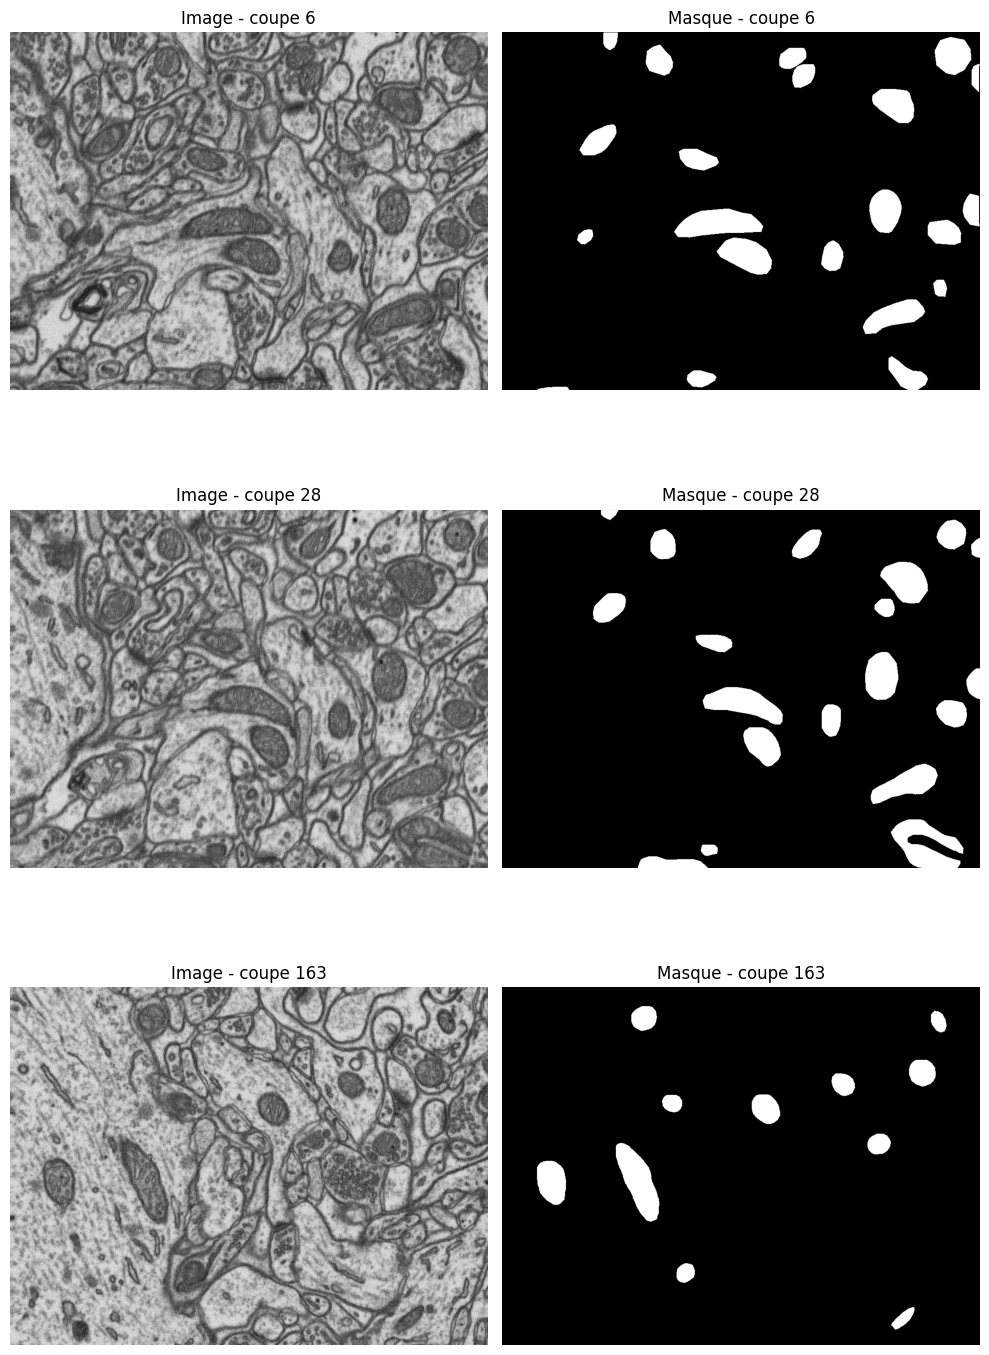

In [7]:
import matplotlib.pyplot as plt
import random

random.seed(42)
n_slices = 3
indices = sorted(random.sample(range(large_images.shape[0]), n_slices))

fig, axes = plt.subplots(n_slices, 2, figsize=(10, 5 * n_slices))

for row, idx in enumerate(indices):
    axes[row, 0].imshow(large_images[idx], cmap='gray')
    axes[row, 0].set_title(f"Image - coupe {idx}")
    axes[row, 0].axis('off')

    axes[row, 1].imshow(large_masks[idx], cmap='gray')
    axes[row, 1].set_title(f"Masque - coupe {idx}")
    axes[row, 1].axis('off')

plt.tight_layout()
plt.show()

In [8]:
def patchify_array(image, patch_size):
    h, w = image.shape
    ph, pw = patch_size
    n_h = h // ph
    n_w = w // pw
    patches = image[:n_h * ph, :n_w * pw].reshape(n_h, ph, n_w, pw)
    patches = patches.swapaxes(1, 2)
    return patches

In [9]:
patch_size = 256
step = 256

all_img_patches = []
for img in range(large_images.shape[0]):
    large_image = large_images[img]
    patches_img = patchify_array(large_image, (patch_size, patch_size))

    for i in range(patches_img.shape[0]):
        for j in range(patches_img.shape[1]):
            single_patch_img = patches_img[i, j, :, :]
            all_img_patches.append(single_patch_img)

images = np.array(all_img_patches)

all_mask_patches = []
for img in range(large_masks.shape[0]):
    large_mask = large_masks[img]
    patches_mask = patchify_array(large_mask, (patch_size, patch_size))

    for i in range(patches_mask.shape[0]):
        for j in range(patches_mask.shape[1]):
            single_patch_mask = patches_mask[i, j, :, :]
            single_patch_mask = (single_patch_mask / 255.).astype(np.uint8)
            all_mask_patches.append(single_patch_mask)

masks = np.array(all_mask_patches)

print("Dimensions des patchs d'images :", images.shape)
print("Dimensions des patchs de masques:", masks.shape)
print("Valeurs uniques des masques    :", np.unique(masks))

Dimensions des patchs d'images : (1980, 256, 256)
Dimensions des patchs de masques: (1980, 256, 256)
Valeurs uniques des masques    : [0 1]


In [10]:
valid_indices = [i for i, mask in enumerate(masks) if mask.max() != 0]

filtered_images = images[valid_indices]
filtered_masks  = masks[valid_indices]

print("Nombre de patchs initiaux   :", images.shape[0])
print("Nombre de patchs conservés  :", filtered_images.shape[0])
print("Patchs supprimés            :", images.shape[0] - filtered_images.shape[0])
print("Dimensions images filtrées  :", filtered_images.shape)
print("Dimensions masques filtrés  :", filtered_masks.shape)

Nombre de patchs initiaux   : 1980
Nombre de patchs conservés  : 1642
Patchs supprimés            : 338
Dimensions images filtrées  : (1642, 256, 256)
Dimensions masques filtrés  : (1642, 256, 256)


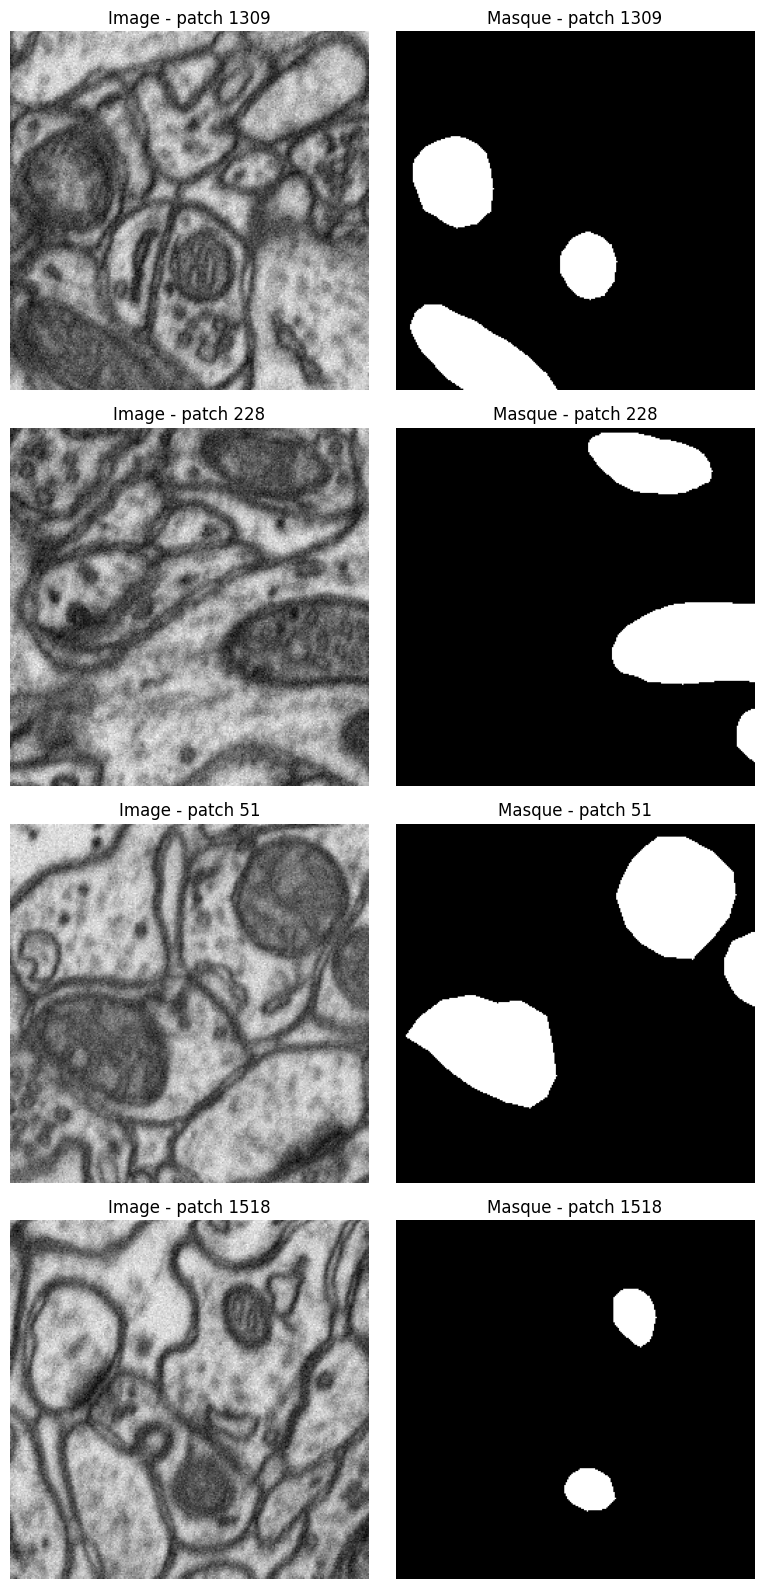

In [11]:
random.seed(42)
n_patches = 4
indices = random.sample(range(filtered_images.shape[0]), n_patches)

fig, axes = plt.subplots(n_patches, 2, figsize=(8, 4 * n_patches))

for row, idx in enumerate(indices):
    axes[row, 0].imshow(filtered_images[idx], cmap='gray')
    axes[row, 0].set_title(f"Image - patch {idx}")
    axes[row, 0].axis('off')

    axes[row, 1].imshow(filtered_masks[idx], cmap='gray')
    axes[row, 1].set_title(f"Masque - patch {idx}")
    axes[row, 1].axis('off')

plt.tight_layout()
plt.show()


In [12]:
from datasets import Dataset
from PIL import Image

dataset_dict = {
    "image": [Image.fromarray(img) for img in filtered_images],
    "label": [Image.fromarray(mask) for mask in filtered_masks],
}

dataset = Dataset.from_dict(dataset_dict)

print(dataset)
print(dataset[0])

Dataset({
    features: ['image', 'label'],
    num_rows: 1642
})
{'image': <PIL.PngImagePlugin.PngImageFile image mode=L size=256x256 at 0x7DBB2C38DD30>, 'label': <PIL.PngImagePlugin.PngImageFile image mode=L size=256x256 at 0x7DBB2C3D1090>}


In [13]:
def get_bounding_box(ground_truth_map):
    y_indices, x_indices = np.where(ground_truth_map > 0)
    x_min, x_max = np.min(x_indices), np.max(x_indices)
    y_min, y_max = np.min(y_indices), np.max(y_indices)

    H, W = ground_truth_map.shape
    x_min = max(0, x_min - np.random.randint(0, 20))
    x_max = min(W, x_max + np.random.randint(0, 20))
    y_min = max(0, y_min - np.random.randint(0, 20))
    y_max = min(H, y_max + np.random.randint(0, 20))

    bbox = [x_min, y_min, x_max, y_max]
    return bbox


### Objet

Cette cellule définit la classe `SAMDataset`, qui fait le pont entre les données préparées précédemment (patchs d'images et de masques stockés dans un objet HuggingFace) et la boucle d'entraînement PyTorch. Elle implémente l'interface `torch.utils.data.Dataset`, ce qui la rend directement compatible avec le `DataLoader` de PyTorch.

### Position dans le pipeline

Le flux de données de l'entraînement traverse trois couches successives, chacune avec une responsabilité distincte :

| Couche | Responsabilité |
|---|---|
| `datasets.Dataset` (HuggingFace) | Stockage, accès indexé, opérations de haut niveau (shuffle, split) |
| `SAMDataset` (cette classe) | Transformation d'un exemple brut en un dictionnaire de tenseurs prêt pour le modèle |
| `DataLoader` (PyTorch) | Regroupement en batchs, mélange, parallélisation |

Cette séparation est volontaire. Les opérations de stockage et de manipulation d'ensemble restent dans HuggingFace, où elles sont optimisées. La logique propre au modèle — calcul du prompt, appel au processor, préparation des tenseurs — est isolée dans cette classe. Le `DataLoader` se limite à son rôle de batching.

### Interface implémentée

Un `Dataset` PyTorch doit exposer deux méthodes.

`__len__` renvoie le nombre d'exemples. Le `DataLoader` s'en sert pour calculer le nombre de batchs par époque et pour décider quand arrêter l'itération.

`__getitem__` prend un indice et renvoie un exemple. C'est ici que se trouve toute la logique de transformation. Le `DataLoader` appelle cette méthode une fois par exemple, en parallèle sur plusieurs workers si demandé, puis assemble les résultats en batchs.

### Déroulement de `__getitem__`

**Extraction de l'exemple brut.** L'accès `self.dataset[idx]` renvoie un dictionnaire à deux clés : `image` contient une image PIL en niveaux de gris, `label` contient le masque correspondant, également sous forme PIL. Ce sont les objets construits à la cellule 9.

**Conversion du masque en tableau NumPy.** L'image reste en PIL, car c'est le format attendu par le processor. Le masque, lui, est converti en tableau NumPy immédiatement. Deux raisons : le calcul de la boîte englobante se fait en NumPy, et le masque sera réutilisé plus tard comme cible de la fonction de coût.

**Calcul de la boîte englobante.** L'appel à `get_bounding_box` produit une liste `[x_min, y_min, x_max, y_max]` qui servira de prompt.

**Passage par le processor.** `self.processor(image, input_boxes=[[prompt]], return_tensors="pt")` déclenche toute une chaîne de traitements internes : redimensionnement de l'image à 1024×1024 (taille attendue par SAM), normalisation des intensités selon les statistiques du pré-entraînement, conversion en tenseur, encodage de la boîte en une représentation exploitable par le prompt encoder. Le résultat est un dictionnaire contenant notamment `pixel_values` et `input_boxes` sous forme de tenseurs PyTorch.

L'argument `input_boxes=[[prompt]]` mérite une attention particulière : le processor attend une structure à trois niveaux — `[batch][nb_boîtes_par_image][coordonnées]`. Les doubles crochets indiquent donc « un batch d'une image, contenant une seule boîte, de coordonnées `prompt` ».

**Suppression de la dimension de batch.** Par convention, le processor traite toujours ses entrées comme un batch. Il renvoie donc des tenseurs de forme `(1, ...)` alors qu'on manipule ici un seul exemple. L'expression `{k: v.squeeze(0) for k, v in inputs.items()}` retire cette dimension superflue. Le `DataLoader` rajoutera ensuite la sienne, et sans ce `squeeze`, on obtiendrait une dimension de batch en double.

**Ajout du masque de référence.** Le masque est stocké sous la clé `ground_truth_mask` dans le dictionnaire renvoyé. Il ne passe volontairement pas par le processor, car il ne doit subir aucune normalisation : c'est une cible binaire qui sera comparée directement aux prédictions du modèle. Sa conversion en tenseur flottant sera faite explicitement dans la boucle d'entraînement, au moment du calcul de la perte.

### Résultat

Chaque appel à `__getitem__` renvoie un dictionnaire de tenseurs PyTorch contenant l'image encodée, la boîte prompt encodée, et le masque de référence. Ce format est exactement celui qu'attendent le modèle et la fonction de coût aux cellules suivantes.

In [14]:
from torch.utils.data import Dataset

class SAMDataset(Dataset):

    def __init__(self, dataset, processor):
        self.dataset = dataset
        self.processor = processor

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = item["image"]
        ground_truth_mask = np.array(item["label"])

        prompt = get_bounding_box(ground_truth_mask)

        inputs = self.processor(
            image,
            input_boxes=[[prompt]],
            return_tensors="pt"
        )

        inputs = {k: v.squeeze(0) for k, v in inputs.items()}
        inputs["ground_truth_mask"] = ground_truth_mask

        return inputs

## Cellule 12 — Instanciation du processor, du modèle et du DataLoader

### Objet

Cette cellule instancie les trois composants qui orchestrent l'entraînement : le processor, qui prépare les entrées du modèle ; le modèle SAM lui-même, dont seule une partie est entraînée ; et le DataLoader, qui alimente la boucle d'entraînement en batchs.

### Le processor : `SamProcessor`

Le processor est l'interface entre les données brutes (images PIL, boîtes englobantes sous forme de listes Python) et les tenseurs attendus par le modèle. Il regroupe plusieurs opérations qui doivent être parfaitement cohérentes avec le pré-entraînement de SAM.

**Redimensionnement.** SAM a été entraîné sur des images de 1024×1024 pixels. Le processor redimensionne donc chaque patch d'entrée à cette taille, quelle que soit sa dimension d'origine. Un patch de 256×256 est agrandi à 1024×1024. Cette étape est invisible pour l'utilisateur mais essentielle : elle explique pourquoi le modèle peut traiter des patchs de tailles variées sans modification.

**Normalisation.** Les intensités sont normalisées selon les statistiques (moyenne et écart-type par canal) utilisées lors du pré-entraînement de SAM. Cette étape garantit que les valeurs d'entrée se situent dans la plage attendue par le réseau.

**Encodage du prompt.** La boîte englobante fournie sous forme de liste `[x_min, y_min, x_max, y_max]` est convertie en un tenseur et subit un encodage positionnel, de la même manière que les points. Le processor gère la structure à trois niveaux `[batch][nb_boîtes][coordonnées]` et prépare les tenseurs `input_boxes`.

**Conversion en tenseurs.** Avec `return_tensors="pt"`, le processor renvoie des tenseurs PyTorch plutôt que des tableaux NumPy. C'est cette conversion qui rend la sortie directement utilisable par le modèle.

### Le modèle : `SamModel`

`SamModel` est l'implémentation HuggingFace de l'architecture SAM, chargée avec les poids du checkpoint `facebook/sam-vit-base`. L'architecture comporte trois blocs.

**`vision_encoder` (ViT-B).** C'est un Vision Transformer de taille "base". Il transforme l'image d'entrée en une représentation vectorielle dense de haute dimension. Ce bloc est le plus lourd en paramètres et en calcul. Il est **gelé** dans notre entraînement : ses poids ne sont pas mis à jour.

**`prompt_encoder`.** Il encode la boîte englobante en une représentation vectorielle. Ce bloc est également **gelé**.

**`mask_decoder`.** C'est un transformateur léger qui combine la représentation de l'image et celle du prompt pour produire le masque de segmentation. C'est le **seul bloc entraîné**. Cette stratégie est standard pour le fine-tuning de SAM sur des jeux de données de taille modeste : elle préserve les représentations visuelles générales apprises sur des millions d'images, tout en adaptant le décodeur à la tâche spécifique (ici, la segmentation de mitochondries en microscopie électronique).

### Gel des paramètres

La boucle

```python
for name, param in model.named_parameters():
    if name.startswith("vision_encoder") or name.startswith("prompt_encoder"):
        param.requires_grad_(False)

In [15]:
from transformers import SamProcessor, SamModel
from torch.utils.data import DataLoader

processor = SamProcessor.from_pretrained("facebook/sam-vit-base")

train_dataset = SAMDataset(dataset=dataset, processor=processor)

example = train_dataset[0]
for k, v in example.items():
    print(k, v.shape)

train_dataloader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    drop_last=False
)

model = SamModel.from_pretrained("facebook/sam-vit-base")

for name, param in model.named_parameters():
    if name.startswith("vision_encoder") or name.startswith("prompt_encoder"):
        param.requires_grad_(False)

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

pixel_values torch.Size([3, 1024, 1024])
original_sizes torch.Size([2])
reshaped_input_sizes torch.Size([2])
input_boxes torch.Size([1, 4])
ground_truth_mask (256, 256)


config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

### Objet

Cette cellule prépare tout ce qui doit exister avant le premier pas d'entraînement : découpage du jeu de données en un ensemble d'entraînement et un ensemble de validation, création des deux DataLoaders correspondants, instanciation du modèle, gel des blocs pré-entraînés, définition de l'optimiseur, de la fonction de coût et de la métrique d'évaluation, et initialisation des structures qui recevront l'historique.

### Split 80/20

Le jeu de données filtré est découpé en deux sous-ensembles disjoints via `Dataset.train_test_split`, avec une graine fixée pour garantir la reproductibilité. 80 % des patchs servent à l'entraînement, 20 % à la validation. Le DataLoader d'entraînement mélange les exemples à chaque époque ; celui de validation conserve un ordre fixe pour que les métriques soient comparables d'une époque à l'autre.

Un point mérite d'être signalé pour la rigueur scientifique : le split est effectué au niveau des patchs, et non au niveau des coupes. Deux patchs issus de la même coupe peuvent donc se retrouver, l'un en entraînement, l'autre en validation. Le risque de fuite d'information est faible dans la mesure où les patchs ne se recouvrent pas et où le modèle traite chacun indépendamment, mais une séparation par coupe serait plus stricte. Ce point est documenté ici pour transparence.

### Hyperparamètres

Trente époques sont prévues, avec un batch de 2, un taux d'apprentissage de 1e-5 sur le seul décodeur, et un arrêt anticipé sur la métrique de validation avec une patience de 7 époques.

### Métrique d'évaluation : le coefficient de Dice

Le coefficient de Dice mesure le recouvrement entre un masque prédit et un masque de référence. Il vaut 1 en cas de recouvrement parfait et 0 en l'absence totale de recouvrement. Il est ici calculé sur les masques binarisés à seuil 0.5, après application d'une sigmoïde sur les logits produits par le modèle. Le Dice est choisi comme métrique de suivi et d'arrêt anticipé car il est plus robuste que l'exactitude pixel dans les problèmes de segmentation où les objets sont minoritaires, ce qui est le cas des mitochondries.

### Sauvegarde

Un dossier de checkpoints est créé sur Drive. À chaque époque, les poids courants sont sauvegardés sous un nom numéroté. Le meilleur modèle selon le Dice de validation est sauvegardé séparément. L'historique des métriques est écrit dans un fichier JSON à chaque époque, afin de permettre un tracé ultérieur même en cas d'interruption.

In [16]:
import json
import torch
import monai
from torch.utils.data import DataLoader
from torch.optim import Adam
from transformers import SamProcessor, SamModel

SEED = 42
VAL_RATIO = 0.2
BATCH_SIZE = 2
LEARNING_RATE = 1e-5
NUM_EPOCHS = 30
PATIENCE = 7

CHECKPOINT_DIR = ""
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)

split = dataset.train_test_split(test_size=VAL_RATIO, seed=SEED)
train_hf = split["train"]
val_hf = split["test"]

print("Patchs d'entraînement :", len(train_hf))
print("Patchs de validation  :", len(val_hf))

processor = SamProcessor.from_pretrained("facebook/sam-vit-base")

train_dataset = SAMDataset(dataset=train_hf, processor=processor)
val_dataset = SAMDataset(dataset=val_hf, processor=processor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

model = SamModel.from_pretrained("facebook/sam-vit-base")
for name, param in model.named_parameters():
    if name.startswith("vision_encoder") or name.startswith("prompt_encoder"):
        param.requires_grad_(False)

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

optimizer = Adam(model.mask_decoder.parameters(), lr=LEARNING_RATE, weight_decay=0)
seg_loss = monai.losses.DiceCELoss(sigmoid=True, squared_pred=True, reduction='mean')

def dice_coefficient(pred_logits, gt_mask, threshold=0.5, eps=1e-6):
    pred_prob = torch.sigmoid(pred_logits)
    pred_bin = (pred_prob > threshold).float()
    intersection = (pred_bin * gt_mask).sum()
    union = pred_bin.sum() + gt_mask.sum()
    return (2. * intersection + eps) / (union + eps)

config = {
    "seed": SEED,
    "val_ratio": VAL_RATIO,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "num_epochs": NUM_EPOCHS,
    "patience": PATIENCE,
    "n_train": len(train_hf),
    "n_val": len(val_hf),
    "model": "facebook/sam-vit-base",
    "frozen_blocks": ["vision_encoder", "prompt_encoder"],
}
with open(os.path.join(CHECKPOINT_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=2)

print("Device :", device)

Patchs d'entraînement : 1313
Patchs de validation  : 329


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Device : cuda


### Objet

Cette cellule exécute l'entraînement complet sur les époques prévues. À chaque époque, deux phases se succèdent.

**Phase d'entraînement.** Le modèle est en mode entraînement. Pour chaque batch, une passe avant calcule les masques prédits, la fonction de coût est évaluée, les gradients sont calculés et l'optimiseur met à jour les paramètres du décodeur. Le Dice est calculé sur les prédictions courantes pour suivre l'évolution de la qualité à mesure de l'apprentissage.

**Phase de validation.** Le modèle est en mode évaluation et aucune information de gradient n'est stockée. Les mêmes calculs sont effectués sur l'ensemble de validation, sans mise à jour des poids.

### Suivi et décisions par époque

À la fin de chaque époque, les moyennes des pertes et des Dice d'entraînement et de validation sont enregistrées dans un dictionnaire d'historique. Ce dictionnaire est sauvegardé sur Drive après chaque époque, ce qui permet de tracer les courbes plus tard et de reprendre l'analyse en cas d'interruption de la session Colab.

Les poids courants sont sauvegardés sous un nom numéroté. Un second fichier contient le meilleur modèle observé jusqu'ici selon le Dice de validation : il est écrasé chaque fois que le Dice de validation progresse.

### Arrêt anticipé

Un compteur suit le nombre d'époques consécutives sans amélioration du Dice de validation. Si ce compteur atteint la patience de 7 époques, l'entraînement s'arrête prématurément. Cette stratégie évite de poursuivre l'entraînement lorsque le modèle ne progresse plus sur les données qu'il n'a pas vues, et réduit le risque de surapprentissage.

### Après l'arrêt

Les poids de la dernière époque sont sauvegardés séparément. Le meilleur modèle reste disponible dans le fichier dédié et sera rechargé dans le notebook suivant pour l'évaluation et l'inférence.

### Remarque sur le stockage

Chaque checkpoint pèse environ 375 Mo. Sur 30 époques, cela peut représenter plus de 10 Go sur Google Drive. Si l'espace disponible est insuffisant, il est possible de ne conserver que le meilleur modèle et le dernier, en supprimant les checkpoints intermédiaires au fur et à mesure.

In [17]:
from tqdm import tqdm

history = {
    "train_loss": [],
    "val_loss": [],
    "train_dice": [],
    "val_dice": [],
}

best_val_dice = -1.0
epochs_no_improve = 0

for epoch in range(NUM_EPOCHS):

    model.train()
    epoch_train_losses = []
    epoch_train_dices = []

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{NUM_EPOCHS} [train]"):
        outputs = model(
            pixel_values=batch["pixel_values"].to(device),
            input_boxes=batch["input_boxes"].to(device),
            multimask_output=False
        )

        predicted_masks = outputs.pred_masks.squeeze(1)
        ground_truth_masks = batch["ground_truth_mask"].float().to(device)
        loss = seg_loss(predicted_masks, ground_truth_masks.unsqueeze(1))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_train_losses.append(loss.item())
        with torch.no_grad():
            epoch_train_dices.append(
                dice_coefficient(predicted_masks, ground_truth_masks.unsqueeze(1)).item()
            )

    model.eval()
    epoch_val_losses = []
    epoch_val_dices = []

    with torch.no_grad():
        for batch in tqdm(val_loader, desc=f"Epoch {epoch+1:02d}/{NUM_EPOCHS} [val]  "):
            outputs = model(
                pixel_values=batch["pixel_values"].to(device),
                input_boxes=batch["input_boxes"].to(device),
                multimask_output=False
            )

            predicted_masks = outputs.pred_masks.squeeze(1)
            ground_truth_masks = batch["ground_truth_mask"].float().to(device)
            loss = seg_loss(predicted_masks, ground_truth_masks.unsqueeze(1))

            epoch_val_losses.append(loss.item())
            epoch_val_dices.append(
                dice_coefficient(predicted_masks, ground_truth_masks.unsqueeze(1)).item()
            )

    train_loss = float(np.mean(epoch_train_losses))
    val_loss = float(np.mean(epoch_val_losses))
    train_dice = float(np.mean(epoch_train_dices))
    val_dice = float(np.mean(epoch_val_dices))

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    print(
        f"Epoch {epoch+1:02d} | "
        f"train_loss={train_loss:.4f} val_loss={val_loss:.4f} | "
        f"train_dice={train_dice:.4f} val_dice={val_dice:.4f}"
    )

    torch.save(
        model.state_dict(),
        os.path.join(CHECKPOINT_DIR, f"epoch_{epoch+1:02d}.pth")
    )

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        epochs_no_improve = 0
        torch.save(
            model.state_dict(),
            os.path.join(CHECKPOINT_DIR, "best_model.pth")
        )
        print(f"  Nouveau meilleur val_dice = {best_val_dice:.4f} (sauvegardé)")
    else:
        epochs_no_improve += 1
        print(f"  Pas d'amélioration ({epochs_no_improve}/{PATIENCE})")

    with open(os.path.join(CHECKPOINT_DIR, "training_history.json"), "w") as f:
        json.dump(history, f, indent=2)

    if epochs_no_improve >= PATIENCE:
        print(f"Arrêt anticipé à l'époque {epoch+1}")
        break

torch.save(
    model.state_dict(),
    os.path.join(CHECKPOINT_DIR, "last_model.pth")
)

print(f"Entraînement terminé. Meilleur val_dice = {best_val_dice:.4f}")
print(f"Checkpoints et historique dans : {CHECKPOINT_DIR}")

Epoch 01/30 [val]  : 100%|██████████| 165/165 [02:34<00:00,  1.07it/s]


Epoch 01 | train_loss=0.2152 val_loss=0.1494 | train_dice=0.8312 val_dice=0.8850
  Nouveau meilleur val_dice = 0.8850 (sauvegardé)


Epoch 02/30 [val]  : 100%|██████████| 165/165 [02:34<00:00,  1.07it/s]


Epoch 02 | train_loss=0.1408 val_loss=0.1294 | train_dice=0.8883 val_dice=0.8982
  Nouveau meilleur val_dice = 0.8982 (sauvegardé)


Epoch 03/30 [val]  : 100%|██████████| 165/165 [02:33<00:00,  1.07it/s]


Epoch 03 | train_loss=0.1227 val_loss=0.1201 | train_dice=0.9004 val_dice=0.9048
  Nouveau meilleur val_dice = 0.9048 (sauvegardé)


... (50 outputs left out)

Epoch 29/30 [val]  : 100%|██████████| 165/165 [02:34<00:00,  1.07it/s]


Epoch 29 | train_loss=0.0679 val_loss=0.0749 | train_dice=0.9439 val_dice=0.9387
  Pas d'amélioration (1/7)


Epoch 30/30 [val]  : 100%|██████████| 165/165 [02:35<00:00,  1.06it/s]


Epoch 30 | train_loss=0.0650 val_loss=0.0774 | train_dice=0.9438 val_dice=0.9367
  Pas d'amélioration (2/7)
Entraînement terminé. Meilleur val_dice = 0.9391
Checkpoints et historique dans : /content/drive/MyDrive/ColabNotebooks/models/SAM/mito_checkpoints


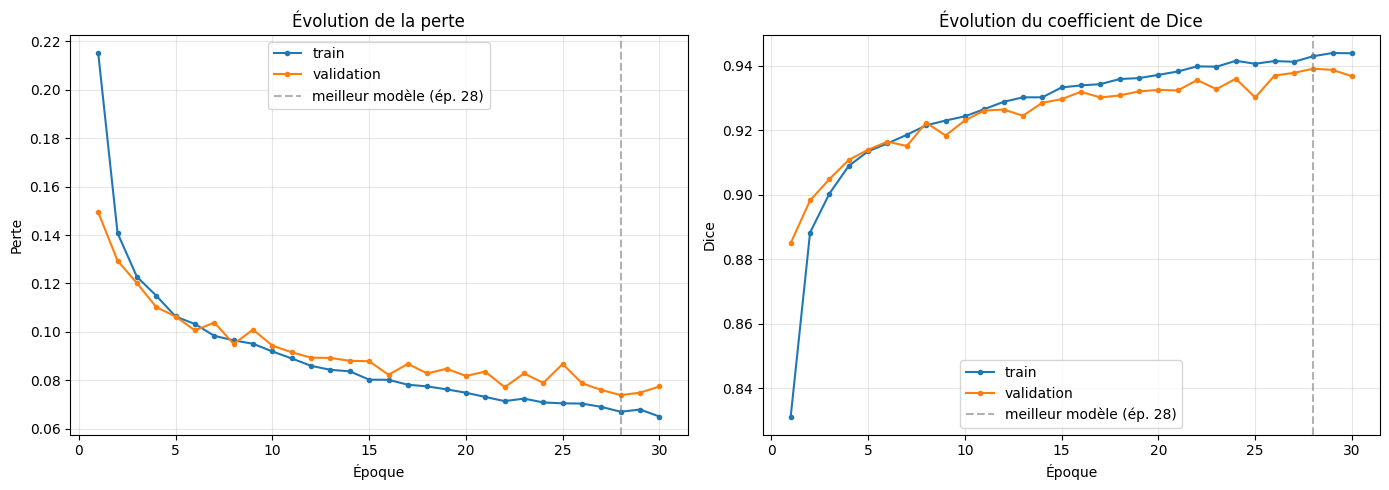

Meilleure époque         : 28
Meilleur val_dice        : 0.9391
Perte de validation      : 0.0739


In [7]:
import json
import numpy as np
import matplotlib.pyplot as plt
import random
CHECKPOINT_DIR = "/content/drive/MyDrive/ColabNotebooks/models/SAM/mito_checkpoints"
with open(os.path.join(CHECKPOINT_DIR, "training_history.json"), "r") as f:
    history = json.load(f)

epochs = np.arange(1, len(history["train_loss"]) + 1)
best_epoch = int(np.argmax(history["val_dice"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["train_loss"], label="train", marker="o", markersize=3)
axes[0].plot(epochs, history["val_loss"], label="validation", marker="o", markersize=3)
axes[0].axvline(best_epoch, color="gray", linestyle="--", alpha=0.6, label=f"meilleur modèle (ép. {best_epoch})")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Perte")
axes[0].set_title("Évolution de la perte")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_dice"], label="train", marker="o", markersize=3)
axes[1].plot(epochs, history["val_dice"], label="validation", marker="o", markersize=3)
axes[1].axvline(best_epoch, color="gray", linestyle="--", alpha=0.6, label=f"meilleur modèle (ép. {best_epoch})")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Dice")
axes[1].set_title("Évolution du coefficient de Dice")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, "training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"Meilleure époque         : {best_epoch}")
print(f"Meilleur val_dice        : {history['val_dice'][best_epoch-1]:.4f}")
print(f"Perte de validation      : {history['val_loss'][best_epoch-1]:.4f}")